# 05 · kallisto vs STAR
**Goal:** do the two quantification methods give the same biological answers?
**Input:** kallisto output (02) and STAR counts (01). **Output:** summary tables in `results/compare/`.
**Kernel:** **R** (`ir`) · **Time:** ~3 min.

Both methods start from the same trimmed reads and the same GENCODE vM25 annotation, and go through the same DESeq2 code (`run_dds`, `run_de`), including the exclusion of outlier SRR21355389 from the aging analysis (notebook 03). Differences therefore come from the counting method only. Measures used: **Spearman correlation** (agreement of rankings; 1 = identical), **Jaccard index** (shared ÷ combined number of DEGs), and *same direction* (share of shared DEGs whose log2FC has the same sign). See [docs/glossary.md](../docs/glossary.md).

In [1]:
# txi: kallisto counts; star: STAR counts (genes x runs); both use GENCODE gene ids
source('../R/helpers.R')
samples <- load_samples()
x <- load_txi(rownames(samples)); txi <- x$txi; genes <- x$genes
STAR_COUNTS <- file.path(ROOT, 'results/star/counts_unstranded.csv.gz')
star <- load_star_counts(STAR_COUNTS)[, rownames(samples)]
cat('kallisto', nrow(txi$counts), 'genes | STAR', nrow(star), 'genes | shared', length(intersect(rownames(txi$counts), rownames(star))), '\n')

kallisto 55401 genes | STAR 55401 genes | shared 55401 


## 1 · Counts per sample
Per sample, Spearman correlation of gene counts between the methods. STAR counts only uniquely mapped reads, so its totals are somewhat lower (`ratio_star_kallisto`).

In [2]:
# one row per sample: correlation and total counts (millions) per method
g <- intersect(rownames(txi$counts), rownames(star))
per_sample <- tibble(srr = rownames(samples), group = samples$group,
  spearman = map_dbl(rownames(samples), \(s) cor(txi$counts[g, s], star[g, s], method = 'spearman')),
  kallisto_M = colSums(txi$counts[g, ]) / 1e6, star_M = colSums(star[g, ]) / 1e6) %>% mutate(ratio_star_kallisto = round(star_M / kallisto_M, 2))
per_sample

srr,group,spearman,kallisto_M,star_M,ratio_star_kallisto
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
SRR21355401,aging 3mo,0.8864809,9.376791,7.791090,0.83
SRR21355396,aging 3mo,0.8849298,16.616050,13.812779,0.83
SRR21355392,aging 3mo,0.8893330,10.420880,8.642295,0.83
SRR21355388,aging 3mo,0.8839440,10.959216,9.093284,0.83
SRR21355398,aging 18mo,0.8927948,4.166268,3.427200,0.82
SRR21355394,aging 18mo,0.8880361,5.111428,4.280349,0.84
SRR21355390,aging 18mo,0.8849952,17.467572,14.433441,0.83
SRR21355386,aging 18mo,0.8869804,6.117052,5.111334,0.84
SRR21355397,aging 21mo,0.8861756,9.091901,7.613476,0.84


## 2 · Differential expression with each method

In [4]:
# the four DESeq2 analyses of notebook 03 for each method; counts of up / down DEGs
kal <- run_de(txi, samples, genes)
str <- run_de(star, samples, genes)
bind_rows(kallisto = bind_rows(lapply(kal, n_deg), .id = 'contrast'), STAR = bind_rows(lapply(str, n_deg), .id = 'contrast'), .id = 'method')

method,contrast,up,down
<chr>,<chr>,<int>,<int>
kallisto,aging_18v3,109,31
kallisto,aging_21v3,79,52
kallisto,aDR,65,77
kallisto,YMP,19,19
STAR,aging_18v3,121,29
STAR,aging_21v3,102,72
STAR,aDR,75,121
STAR,YMP,10,13


### Agreement per contrast
`total_DEG_*` = all DEGs of each method (as in the table above). The other columns use only genes with a valid p-value in **both** methods (`genes_tested_both`; each method filters low-count genes itself), so `DEG_*` can be smaller than the totals.
`jaccard` = shared ÷ combined DEGs; `same_direction` = share of shared DEGs with the same sign; `lfc_spearman_all` / `_sig` = rank correlation of log2FC over all tested genes / over genes significant in either method.

In [5]:
# agreement table per comparison
cmp <- bind_rows(lapply(names(kal), \(n) compare_contrast(kal[[n]], str[[n]]) %>% mutate(contrast = n))) %>% relocate(contrast)
cmp

contrast,total_DEG_kallisto,total_DEG_star,genes_tested_both,DEG_kallisto,DEG_star,shared,jaccard,same_direction,lfc_spearman_all,lfc_spearman_sig
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
aging_18v3,140,150,14846,124,149,93,0.52,1,0.800,0.903
aging_21v3,131,174,16086,122,174,96,0.48,1,0.785,0.956
aDR,142,196,13595,139,196,91,0.37,1,0.831,0.928
YMP,38,23,13176,29,23,19,0.58,1,0.850,0.860


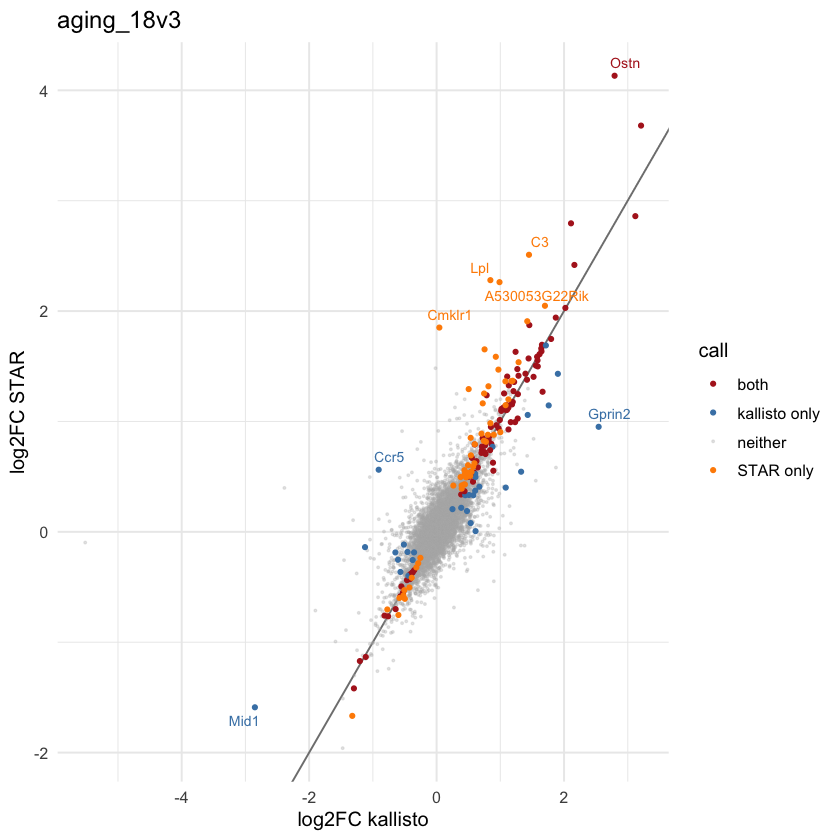

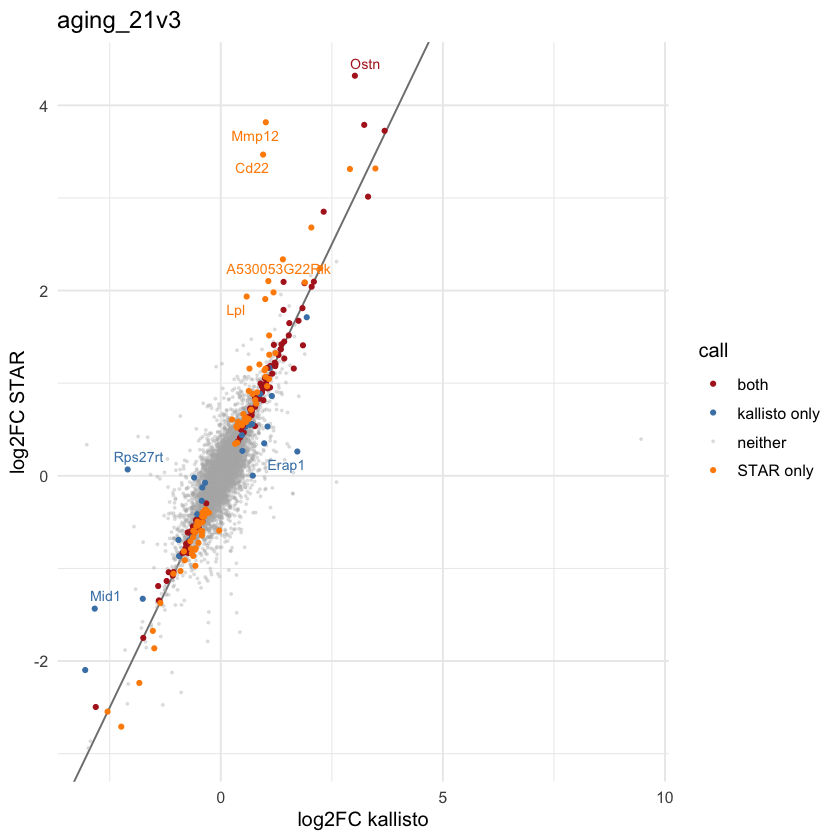

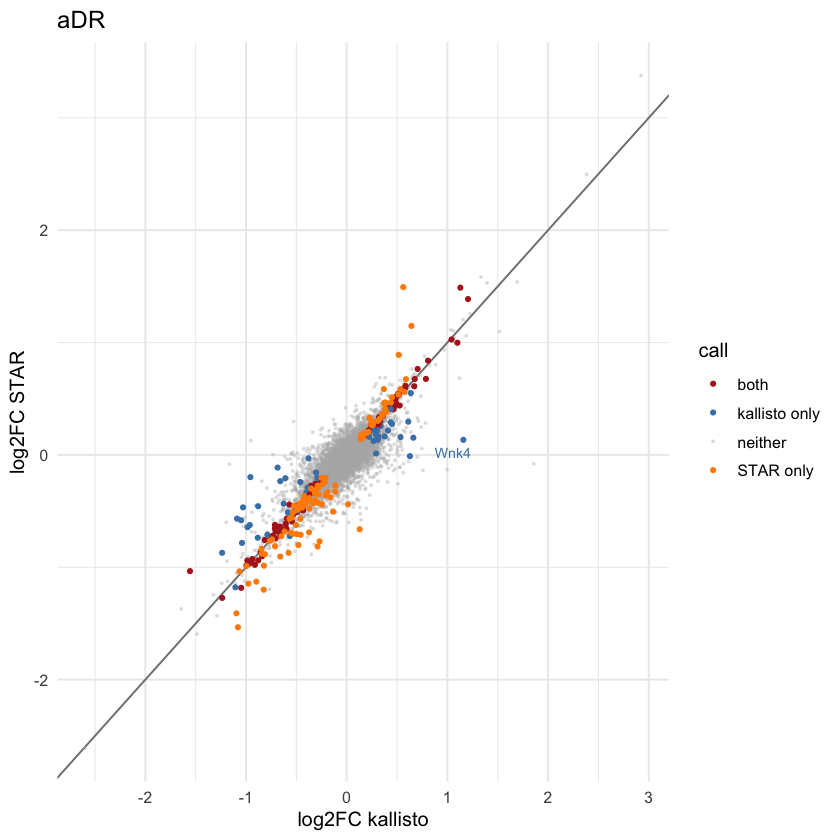

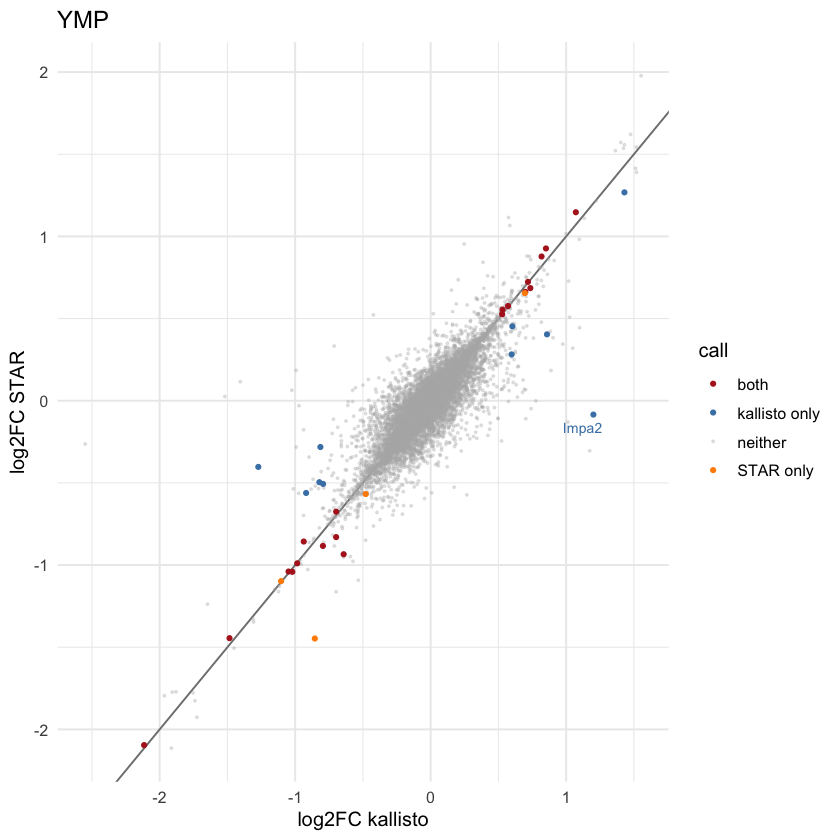

In [6]:
# log2FC kallisto (x) vs STAR (y) per gene; colour = which method calls the gene a DEG
plots <- lapply(names(kal), \(n) lfc_scatter(kal[[n]], str[[n]], n))
for (p in plots) print(p)

## 3 · Genes called by only one method
Are the disagreements mostly lowly expressed genes? `median_baseMean` = median of the genes' average normalised count.

In [7]:
# per comparison: genes called by both / only one method, with typical expression
only <- function(a, b, alpha = 0.05) inner_join(a, b, by = 'gene_id', suffix = c('_k', '_s')) %>% filter(!is.na(padj_k), !is.na(padj_s)) %>%
  mutate(call = case_when(padj_k < alpha & padj_s < alpha ~ 'both', padj_k < alpha ~ 'kallisto only', padj_s < alpha ~ 'STAR only', TRUE ~ 'neither'))
bind_rows(lapply(names(kal), \(cn) only(kal[[cn]], str[[cn]]) %>% filter(call != 'neither') %>% group_by(call) %>%
  summarise(n_genes = n(), median_baseMean = round(median((baseMean_k + baseMean_s) / 2)), .groups = 'drop') %>% mutate(contrast = cn))) %>% relocate(contrast)

contrast,call,n_genes,median_baseMean
<chr>,<chr>,<int>,<dbl>
aging_18v3,STAR only,56,90
aging_18v3,both,93,98
aging_18v3,kallisto only,31,182
aging_21v3,STAR only,78,122
aging_21v3,both,96,162
aging_21v3,kallisto only,26,154
aDR,STAR only,105,359
aDR,both,91,519
aDR,kallisto only,48,428


## 4 · Genes highlighted in the paper
Aging genes (C4b, Trem2, …) and circadian-clock genes induced by dietary restriction (Cry1, Usp2, Ciart, …) in both methods.

In [8]:
# log2FC and padj of the paper's genes, kallisto next to STAR
key <- list(aging_21v3 = c('C4b', 'Trem2', 'Gpr17', 'Gfap', 'Ctss', 'Tyrobp'), aDR = c('Cry1', 'Usp2', 'Ciart', 'Cirbp', 'Dbp'))
bind_rows(lapply(names(key), \(n) {
  f <- \(r, m) r[[n]] %>% filter(symbol %in% key[[n]]) %>% transmute(contrast = n, symbol, !!paste0('lfc_', m) := round(log2FoldChange, 2), !!paste0('padj_', m) := signif(padj, 2))
  inner_join(f(kal, 'kallisto'), f(str, 'STAR'), by = c('contrast', 'symbol'))
}))

contrast,symbol,lfc_kallisto,padj_kallisto,lfc_STAR,padj_STAR
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
aging_21v3,C4b,1.88,5.9e-18,2.08,3.3e-27
aging_21v3,Gfap,0.85,9.2e-10,0.85,6.1e-12
aging_21v3,Ctss,0.98,9.8e-08,0.98,3.5e-09
aging_21v3,Tyrobp,1.23,4.9e-06,1.21,6.0e-07
aging_21v3,Trem2,1.35,3.6e-05,1.37,8.8e-06
aging_21v3,Gpr17,-1.38,7.5e-04,-1.35,3.8e-05
aDR,Ciart,0.81,2.8e-08,0.84,2.1e-13
aDR,Dbp,0.41,3.6e-04,0.44,1.9e-04
aDR,Cirbp,0.55,7.6e-04,0.58,2.5e-04


## 5 · Save

In [9]:
# agreement tables for the report (per-gene STAR tables stay out of git)
dir.create(file.path(ROOT, 'results/compare'), showWarnings = FALSE)
write_csv(cmp, file.path(ROOT, 'results/compare/de_agreement.csv'))
write_csv(per_sample, file.path(ROOT, 'results/compare/counts_per_sample.csv'))
imap(str, \(r, n) write_csv(r, file.path(ROOT, 'results/compare', paste0('star_', n, '.csv')))) %>% invisible()
list.files(file.path(ROOT, 'results/compare'))

[1] "counts_per_sample.csv" "de_agreement.csv"      "star_aDR.csv"         
[4] "star_aging_18v3.csv"   "star_aging_21v3.csv"   "star_YMP.csv"